Identifikasi dataset:

Tujuan: memprediksi tingkat kualitas red wine

Independent variable:
- Fixed acidity
- Volatile acidity
- Citric acid
- Residual sugar
- Chlorides
- Free sulfur dioxide
- Total sulfur dioxide
- Density
- pH
- Sulphates
- Alcohol

Dependent variable: quality

Kelas target: nilai kualitas yang tersedia, seperti 3, 4, 5, 6, 7, dan 8

Algoritma: Random Forest

Alasan identifikasi: Dataset memiliki beberapa nilai target kualitas. Dalam praktikum ini setiap nilai kualitas diperlakukan sebagai satu kelas tersendiri

In [21]:
# 1. Import Library

import pandas as pd
import numpy as np
import time

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
# 2. Membaca Dataset

df = pd.read_csv("winequality-red.csv")

print("Ukuran Dataset:", df.shape)
print(df.head())
print("\nNama kolom:")
print(df.columns.tolist())

Ukuran Dataset: (1599, 12)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8     

In [23]:
# 3. Memeriksa Dataset

print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Duplikat:")
print(df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides  

In [24]:
# 4. Membersihkan Dataset

df = df.drop_duplicates()
df = df.dropna()

print("Ukuran Dataset Setelah Dibersihkan:", df.shape)

Ukuran Dataset Setelah Dibersihkan: (1359, 12)


In [25]:
# 5. Menentukan Fitur dan Target

X = df.drop(columns=["quality"])
y = df["quality"]

print("Jumlah Fitur:", X.shape[1])
print("Jumlah Kategori:", y.nunique())

print("\nDistribusi Target:")
print(y.value_counts().sort_index())

Jumlah Fitur: 11
Jumlah Kategori: 6

Distribusi Target:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [26]:
# 5. Menentukan Fitur dan Target

X = df.drop(columns=["quality"])
y = df["quality"]

print("Jumlah Fitur:", X.shape[1])
print("Jumlah Kategori:", y.nunique())

print("\nDistribusi Target:")
print(y.value_counts().sort_index())

Jumlah Fitur: 11
Jumlah Kategori: 6

Distribusi Target:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [27]:
# 7. Membuat Model Random Forest

model = RandomForestClassifier(
    n_estimators=50,
    max_depth=12,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Model berhasil dibuat!")

Model berhasil dibuat!


In [28]:
# 8. Training Model

start_time = time.time()

model.fit(X_train, y_train)

end_time = time.time()

print("Training selesai!")
print("Waktu Training:", round(end_time - start_time, 2), "detik")

Training selesai!
Waktu Training: 0.24 detik


In [29]:
# 9. Melakukan Prediksi

y_pred = model.predict(X_test)

print("Prediksi selesai!")
print(y_pred[:10])

Prediksi selesai!
[5 6 6 6 5 5 6 5 7 6]


In [30]:
# 10. Menghitung Akurasi

accuracy = accuracy_score(y_test, y_pred)

print("Akurasi Model:", round(accuracy * 100, 2), "%")

Akurasi Model: 61.76 %


In [31]:
# 11. Classification Report

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.68      0.73      0.71       116
           6       0.57      0.67      0.62       107
           7       0.55      0.33      0.42        33
           8       0.00      0.00      0.00         3

    accuracy                           0.62       272
   macro avg       0.30      0.29      0.29       272
weighted avg       0.58      0.62      0.59       272



In [32]:
# 12. Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

print(cm)

[[ 0  0  1  1  0  0]
 [ 0  0  9  2  0  0]
 [ 0  0 85 30  1  0]
 [ 0  0 28 72  7  0]
 [ 0  0  2 20 11  0]
 [ 0  0  0  2  1  0]]


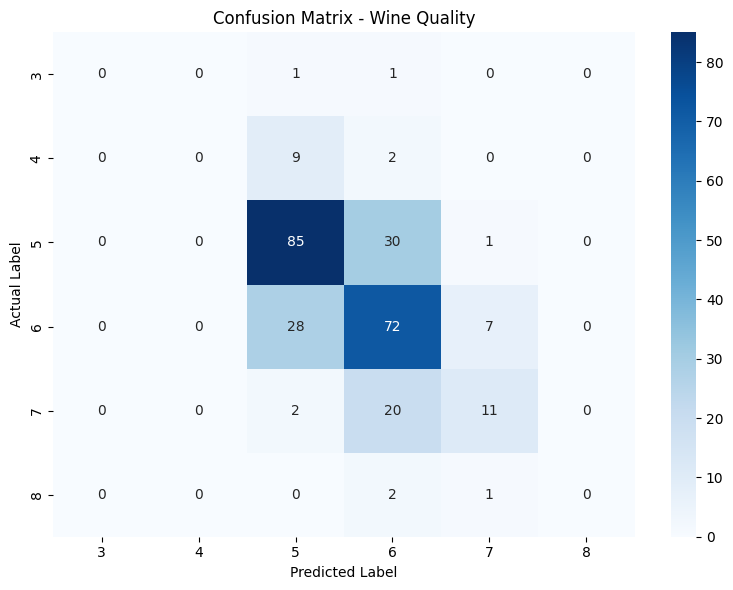

In [33]:
# 13. Visualisasi Confusion Matrix

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix - Wine Quality")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [34]:
# 14. Feature Importance

importance = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.to_string(index=False))

               Fitur  Importance
             alcohol    0.176969
           sulphates    0.114821
    volatile acidity    0.103035
total sulfur dioxide    0.100647
             density    0.086352
           chlorides    0.081415
      residual sugar    0.071505
         citric acid    0.071106
                  pH    0.070402
 free sulfur dioxide    0.063211
       fixed acidity    0.060537


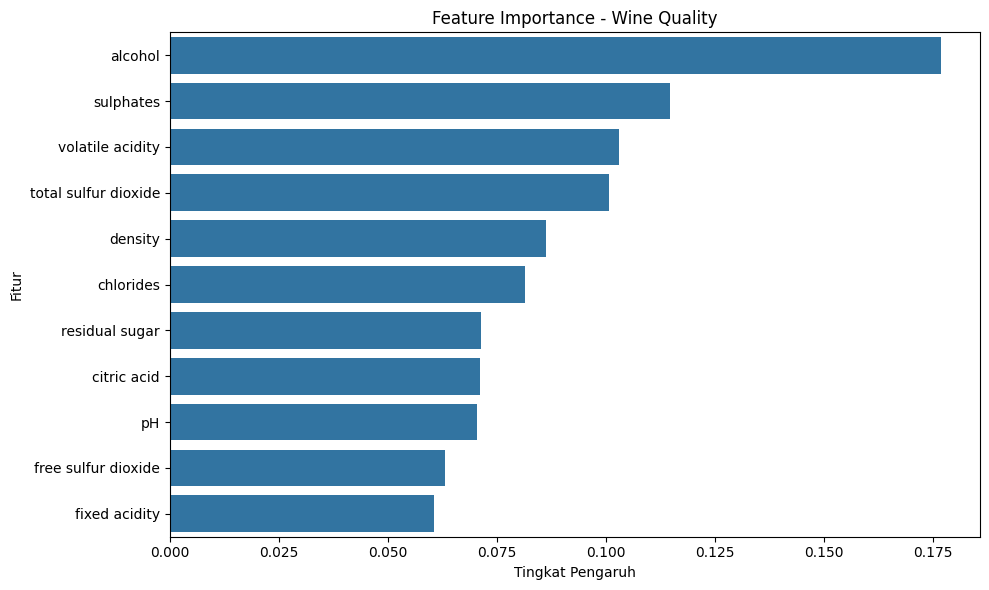

In [35]:
# 15. Visualisasi Feature Importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Fitur"
)

plt.title("Feature Importance - Wine Quality")
plt.xlabel("Tingkat Pengaruh")
plt.ylabel("Fitur")

plt.tight_layout()
plt.show()

Analisis dataset: Red Wine Quality termasuk Multiclass Classification apabila variabel quality diperlakukan sebagai kategori. Random Forest digunakan untuk mempelajari hubungan antara karakteristik kimia wine dengan tingkat kualitasnya

Setiap nilai kualitas diprediksi sebagai kelas tersendiri. Evaluasi dilakukan menggunakan accuracy, precision, recall, F1-score, dan confusion matrix